# **MODELO DE CLASIFICACIÓN**

***El siguiente modelo clasifica prendas de Vestir del dataset de Fashion Mnist de Kaggel***

El dataset contiene un total de 70,000 imágenes en escala de grises.

Se divide en dos conjuntos principales:
*   Entrenamiento (Train): 60,000 muestras.
*   Prueba (Test): 10,000 muestras.

Cada muestra es una imagen de 28x28 píxeles. Los valores de los píxeles originalmente oscilan entre 0 y 255, aunque suelen normalizarse al rango de [0, 1] para el entrenamiento.

Clases: Existen 10 categorías de artículos de ropa:
1.   Camiseta/Top (T-shirt/Top)
2.   Pantalón (Trouser)
1.   Suéter (Pullover)
2.   Vestido (Dress)
1.   Abrigo (Coat)
2.   Sandalia (Sandal)
1.   Camisa (Shirt)
2.   Zapatilla (Sneaker)
1.   Bolso (Bag)
2.   Botín (Ankle boot)

El dataset está perfectamente balanceado, lo que significa que cada una de las 10 clases tiene exactamente el mismo número de muestras (6,000 imágenes por clase en el set de entrenamiento y 1,000 en el de prueba).

Importar librerías

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

Descargar dataset

In [3]:
# Descargar el dataset Fashion MNIST
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
print("Dataset Fashion MNIST descargado")

Dataset Fashion MNIST descargado


Normalizar y pasar a flotante las entradas

In [4]:
# Normalizar imágenes al rango de [0, 1] y pasar a flotante
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Convertir etiquetas a formato categórico (One-Hot)
# Esto es REQUISITO para usar categorical_crossentropy
y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
y_test_cat = tf.keras.utils.to_categorical(y_test, 10)

# Nombres de las clases para la visualización
class_names = ['Camiseta/Top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
               'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Botín']

Mostrar 10 imagenes con su ejemplo y clase

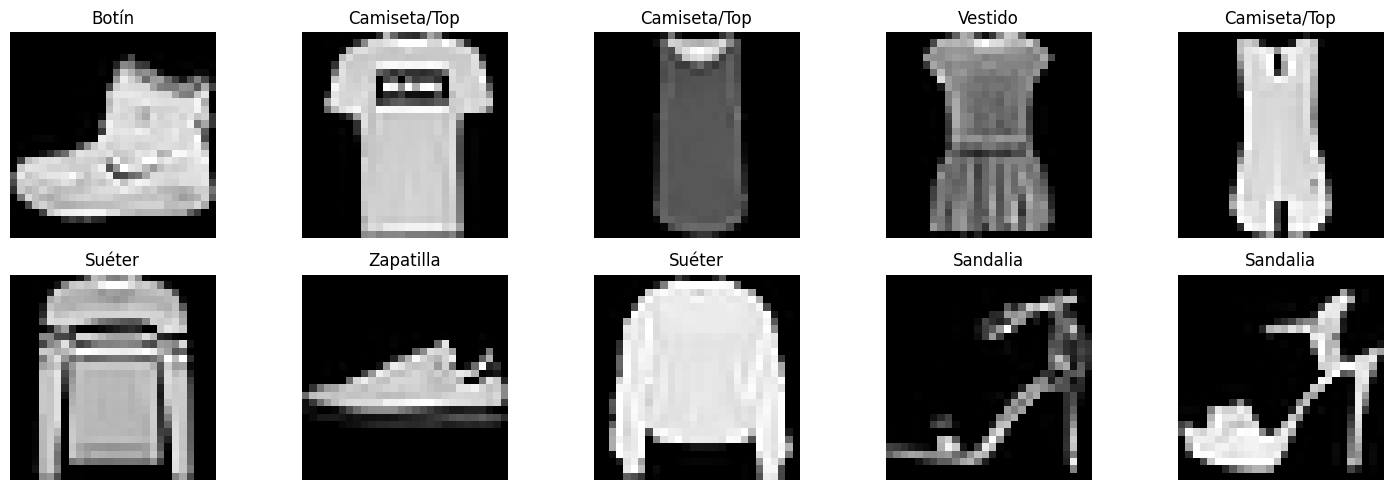

In [5]:
plt.figure(figsize=(15, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

Generar Red Neuronal MLP

In [6]:
# Generar red neuronal MLP (Solo capas Dense)
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Mostrar RNA
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Compilar modelo

In [7]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy', # Función solicitada
              metrics=['accuracy'])

Entrenamiento

In [8]:
history = model.fit(x_train, y_train_cat, epochs=10, validation_split=0.2)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7711 - loss: 0.6547 - val_accuracy: 0.8496 - val_loss: 0.4134
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8549 - loss: 0.4007 - val_accuracy: 0.8657 - val_loss: 0.3708
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8772 - loss: 0.3394 - val_accuracy: 0.8677 - val_loss: 0.3625
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8826 - loss: 0.3207 - val_accuracy: 0.8802 - val_loss: 0.3409
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8889 - loss: 0.3027 - val_accuracy: 0.8728 - val_loss: 0.3435
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8951 - loss: 0.2800 - val_accuracy: 0.8871 - val_loss: 0.3180
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9028 - loss: 0.2639 - val_accuracy: 0.8809 - val_loss: 0.3307
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9053 - loss: 0.2563 - 

Graficar entrenamiento y validación

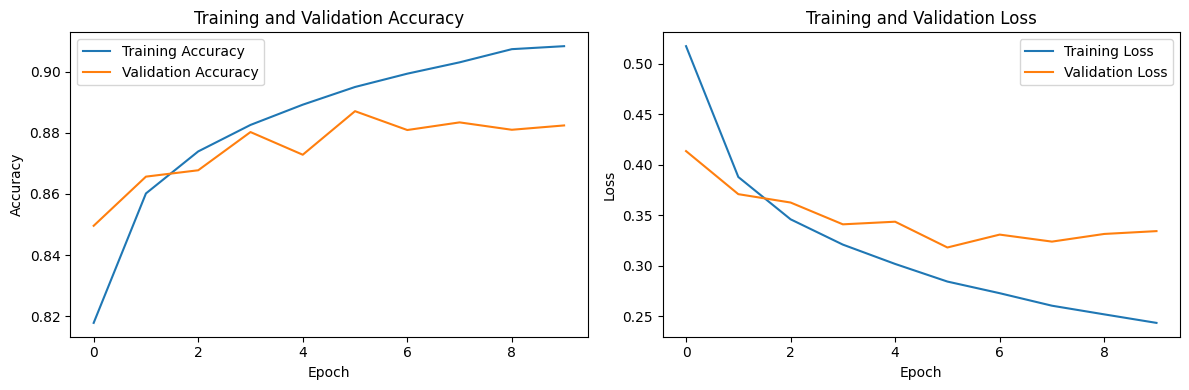

In [9]:
# Solo para verificar que el modelo esté funcionando de manera correcta
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss and Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

Reporte del Acuraccy y loss con el set de prueba

In [10]:
print("\n--- Resultados con el set de prueba ---")
test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=2)
print(f"Accuracy en el conjunto de prueba: {test_acc:.4f}")
print(f"Loss en el conjunto de prueba: {test_loss:.4f}\n")


--- Resultados con el set de prueba ---
313/313 - 1s - 2ms/step - accuracy: 0.8795 - loss: 0.3617
Accuracy en el conjunto de prueba: 0.8795
Loss en el conjunto de prueba: 0.3617



Obtener la matriz de confusión

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


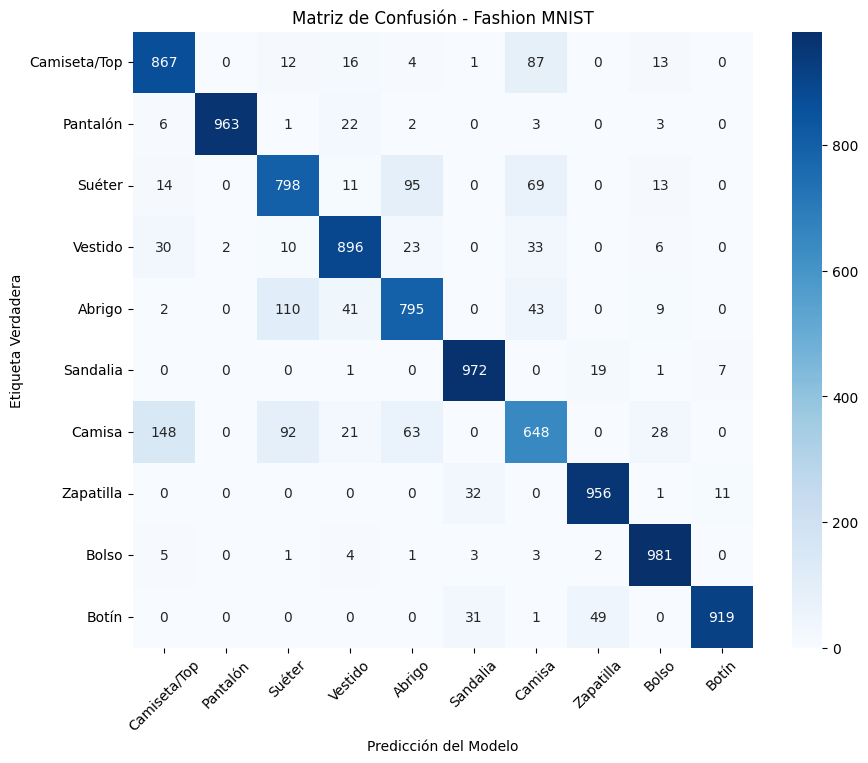

In [11]:
# Generar predicciones por clase
y_pred = model.predict(x_test)
# Convertir las probabilidades a la clase con mayor probabilidad
y_pred_classes = np.argmax(y_pred, axis=1)

# Calcular la matriz de confusión
conf_matrix = confusion_matrix(y_test, y_pred_classes)

# Mostrar la matriz de confusión
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Etiqueta Verdadera')
plt.title('Matriz de Confusión - Fashion MNIST')
plt.xticks(rotation=45)
plt.show()